In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
import warnings
from pathlib import Path
warnings.filterwarnings("ignore")

_HERE = Path.cwd()
_ROOT = _HERE.parent if _HERE.name == "EDA" else _HERE
_EDA  = _ROOT / "EDA"
for _p in (str(_ROOT), str(_EDA)):
    if _p not in sys.path:
        sys.path.insert(0, _p)

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
from scipy.stats import kruskal
from statsmodels.stats.multitest import multipletests

from config import DATA_DIR, PATHS, PARAMS, EDA_BIAS_METRICS, EDA_BIAS_PHENOTYPE_DIR, EDA_COMBINED_METRICS
from analysis.plot_phenotype import check_bias_power_dist, plot_model_auc_grid
from viz_style import FS_ANNOT_SM, apply_style
apply_style()

In [3]:
adata = sc.read_h5ad(PATHS["merged_qc"])
adata = adata[adata.obs["QC_Passed"] == True]

combined_metrics = EDA_COMBINED_METRICS

In [4]:
EXCLUDE_FROM_PHENOTYPE_ANALYSIS = ["Ibarra et al."]  # phenotype~batch confounded by design

In [5]:
bias_metrics = EDA_BIAS_METRICS

### Bias ~ Phenotype Relationship

In [6]:
obs = adata.obs.copy()
all_raw_res = []

for study in obs["Author"].unique():
    if study in EXCLUDE_FROM_PHENOTYPE_ANALYSIS:
        print(f"[Excluded] {study}: phenotype~batch confounded, skipping bias~phenotype analysis")
        continue
    try:
        df_meta = obs[obs["Author"] == study].copy()
        df_meta = df_meta[df_meta["Phenotype_Processed"].notna()]
        df_meta = df_meta[~df_meta["Phenotype_Processed"].isin(["Unknown", "nan"])]
        res_df = check_bias_power_dist(df_meta, bias_metrics, condition_col="Phenotype_Processed")
        if res_df is not None:
            res_df["Author"] = study
            all_raw_res.append(res_df)
    except Exception as e:
        print(f"Skipping {study}: {e}")

[Skip] Too few samples (N < 15).
[Skip] Too few samples (N < 15).
[Excluded] Ibarra et al.: phenotype~batch confounded, skipping bias~phenotype analysis


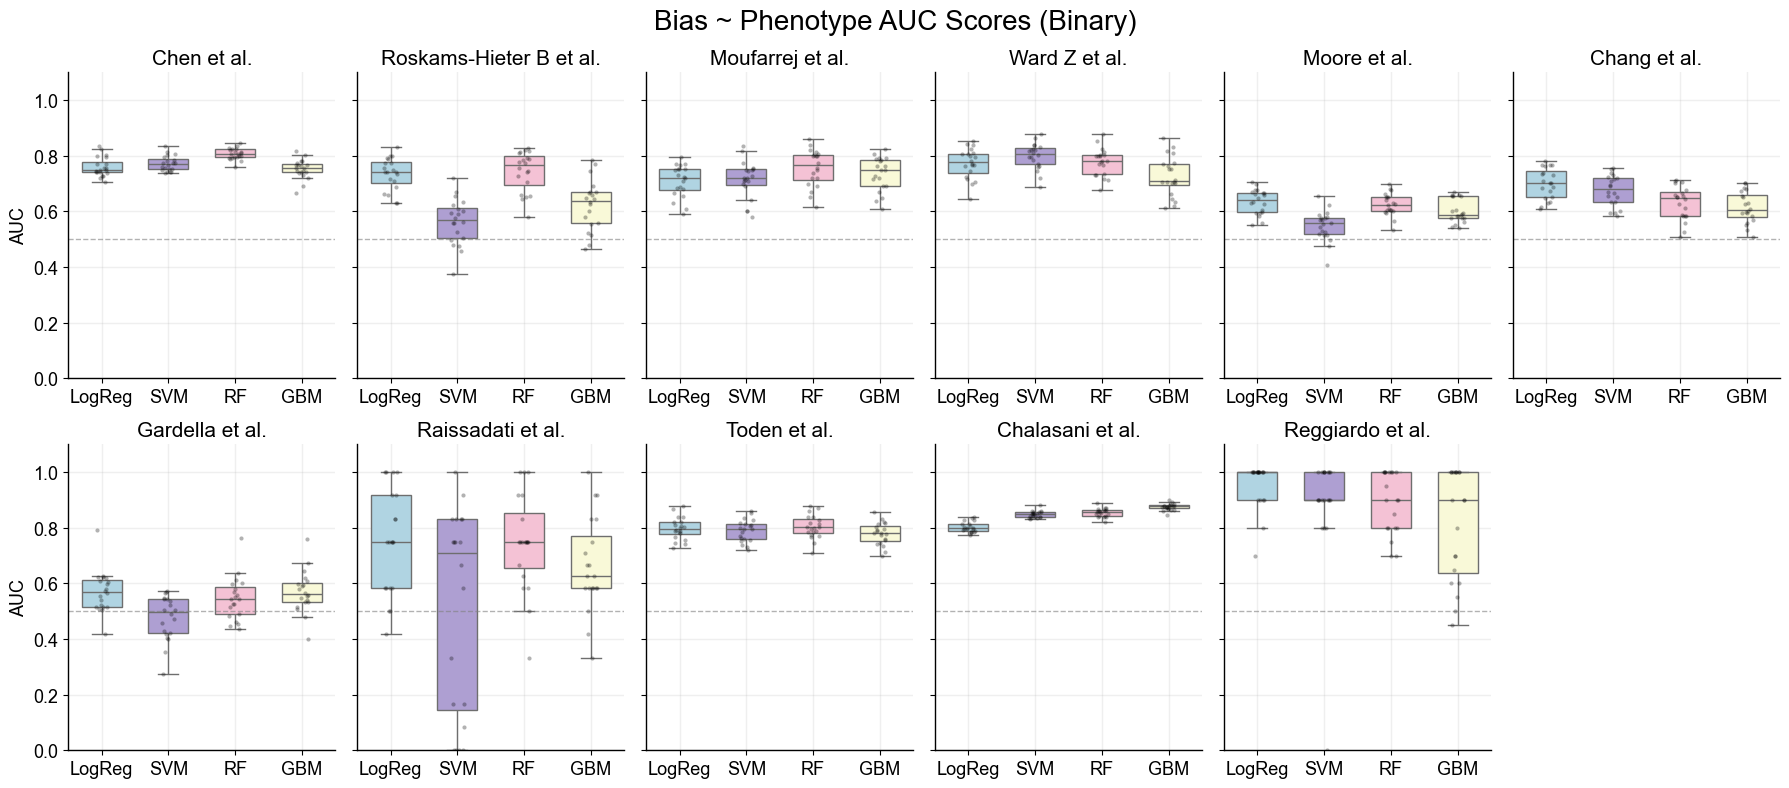

In [7]:
final_df = pd.concat(all_raw_res, axis=0).dropna()
plot_model_auc_grid(final_df, author_col="Author", n_cols=6,
                    save_path=EDA_BIAS_PHENOTYPE_DIR / "bias_power_auc_grid.png")

In [8]:
auc_summary = final_df.groupby(["Author", "Model"])["AUC"].median().unstack()
auc_summary["median_all"] = final_df.groupby("Author")["AUC"].median()
auc_summary.to_csv(EDA_BIAS_PHENOTYPE_DIR / "bias_power_auc_summary.tsv", sep="\t")
auc_summary.round(3).sort_values("median_all")

Model,GBM,LogReg,RF,SVM,median_all
Author,,,,,
Gardella et al.,0.561,0.569,0.544,0.496,0.544
Moore et al.,0.588,0.642,0.625,0.557,0.600
Chang et al.,0.606,0.704,0.649,0.681,0.654
Roskams-Hieter B et al.,0.638,0.742,0.766,0.568,0.664
Moufarrej et al.,0.750,0.721,0.766,0.719,0.735
Raissadati et al.,0.625,0.750,0.750,0.708,0.750
Chen et al.,0.757,0.748,0.805,0.771,0.770
Ward Z et al.,0.710,0.777,0.781,0.808,0.777
Toden et al.,0.780,0.795,0.802,0.795,0.793


### Within-batch Bias ~ Phenotype Confounding Test (Kruskal-Wallis)

In [9]:
obs_rda = adata.obs[~adata.obs["Author"].isin(EXCLUDE_FROM_PHENOTYPE_ANALYSIS)].copy()

stats_results = []
valid_batches = []
for batch_name, group in obs_rda.groupby('Batch_ID'):
    pheno_counts = group['Phenotype_Processed'].dropna().value_counts()
    valid_phenos = pheno_counts[pheno_counts >= 3].index.tolist()
    if len(valid_phenos) >= 2:
        valid_batches.append((batch_name, valid_phenos))
if not valid_batches:
    print("[Result] No multi-phenotype batches found for statistical testing.")

for batch_name, valid_phenos in valid_batches:
    df_batch = obs_rda[(obs_rda['Batch_ID'] == batch_name) & 
                       (obs_rda['Phenotype_Processed'].isin(valid_phenos))]
    
    for bias in bias_metrics:
        if bias not in df_batch.columns:
            continue
        try: 
            groups = [df_batch[df_batch['Phenotype_Processed'] == p][bias].dropna().values for p in valid_phenos]        
            if all(len(g) > 0 for g in groups):
                stat, p_val = kruskal(*groups)
                stats_results.append({'Batch': batch_name, 'Bias': bias, 'p_value': p_val})
            else:
                stats_results.append({'Batch': batch_name, 'Bias': bias, 'p_value': np.nan})
        except Exception:
            stats_results.append({'Batch': batch_name, 'Bias': bias, 'p_value': np.nan})

df_summary = pd.DataFrame(stats_results)
valid_mask = df_summary['p_value'].notna()
df_summary['padj_FDR'] = np.nan
if valid_mask.sum() > 0:
    _, pvals_corrected, _, _ = multipletests(
        df_summary.loc[valid_mask, 'p_value'], 
        alpha=0.05, 
        method='fdr_bh')
    df_summary.loc[valid_mask, 'padj_FDR'] = pvals_corrected
df_summary.to_csv(EDA_BIAS_PHENOTYPE_DIR / "phenotype_bias_confounding_test.tsv", sep="\t", index=False)


In [10]:
custom_x_order = [
    'log(Total Reads)', 
    'Spliced Reads (%)', 
    'gDNA Contamination (Intron/Exon)', 
    'rRNA Fraction', 
    'Platelet Score', 
    'GC Bias', 
    'Gene Length Bias', 
    "RNA Degradation (3' Bias)", 
    'NG80', 
    '(NP80/NG80)'
]
df_pivot = df_summary.pivot(index='Batch', columns='Bias', values='padj_FDR')
df_pivot = df_pivot.reindex(columns=custom_x_order)

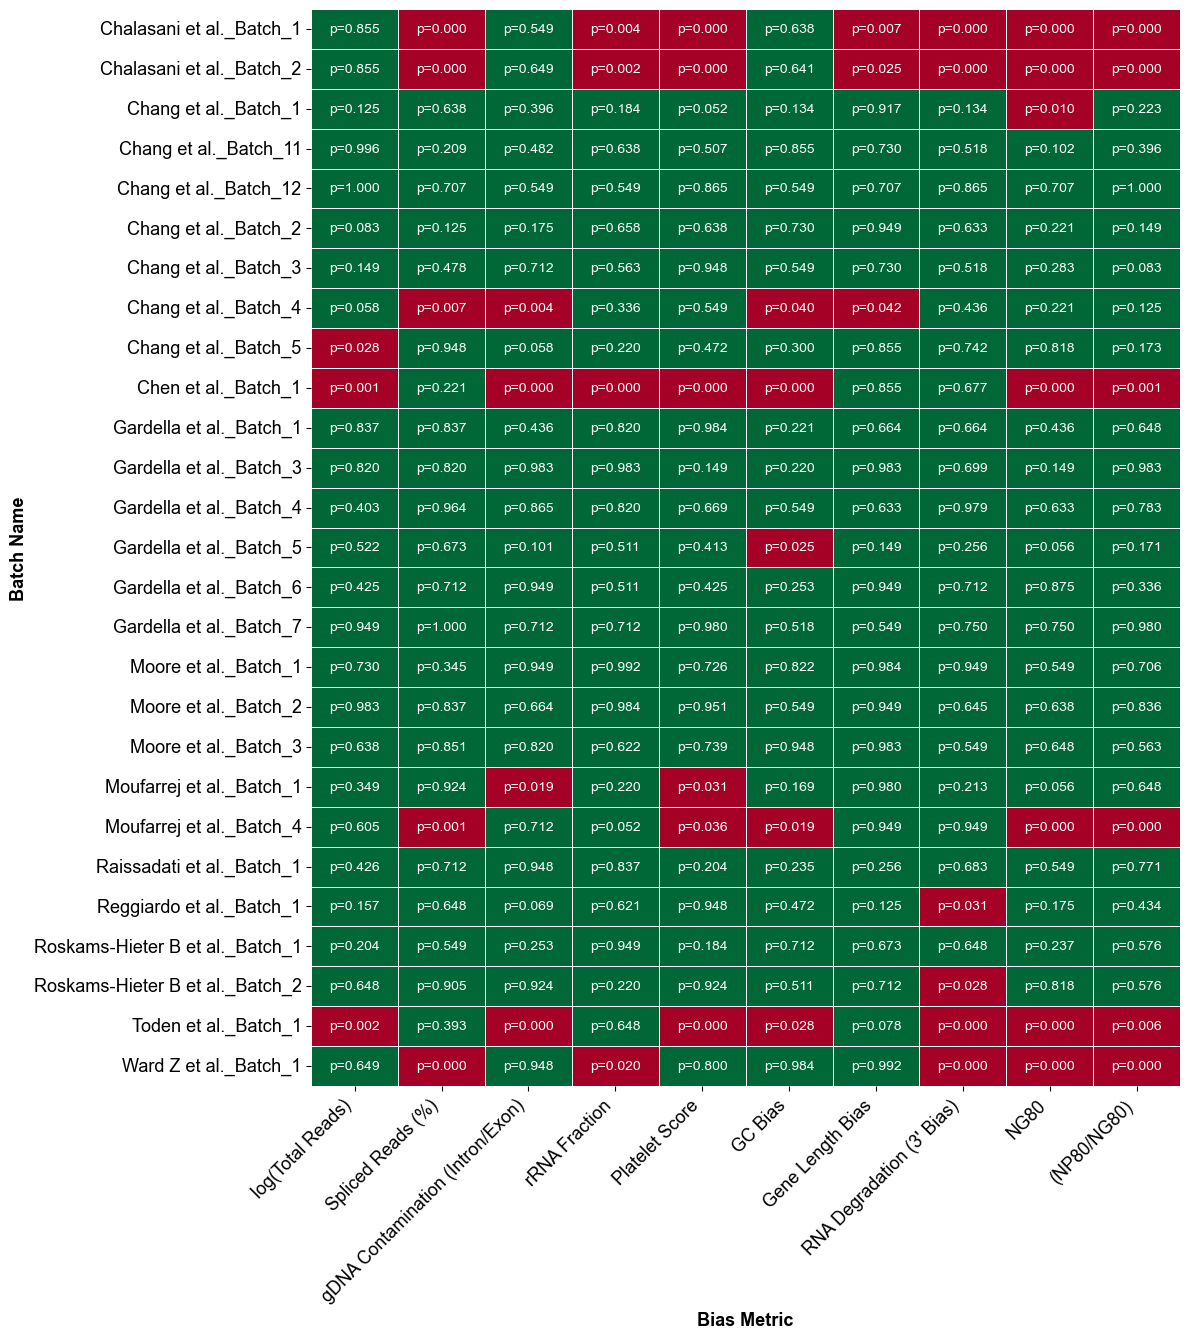

In [11]:
plt.figure(figsize=(min(12, len(bias_metrics) * 1.5), max(4, len(valid_batches) * 0.5)))
heatmap_data = (df_pivot >= 0.05).astype(float)
mask = df_pivot.isna()
annot_data = df_pivot.apply(lambda col: col.map(lambda x: f"p={x:.3f}" if pd.notna(x) else "N/A"))

ax = sns.heatmap(
    heatmap_data, 
    annot=annot_data, 
    fmt="", 
    cmap='RdYlGn', 
    cbar=False, 
    linewidths=0.5, 
    mask=mask,              
)
ax.set_facecolor('lightgray')
plt.xlabel("Bias Metric", fontweight='bold')
plt.ylabel("Batch Name", fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
EDA_BIAS_PHENOTYPE_DIR.mkdir(parents=True, exist_ok=True)
plt.savefig(EDA_BIAS_PHENOTYPE_DIR / "phenotype_bias_confounding_test.png", bbox_inches='tight')
plt.show()

### NG80 in batches where it differs by phenotype (direction check)

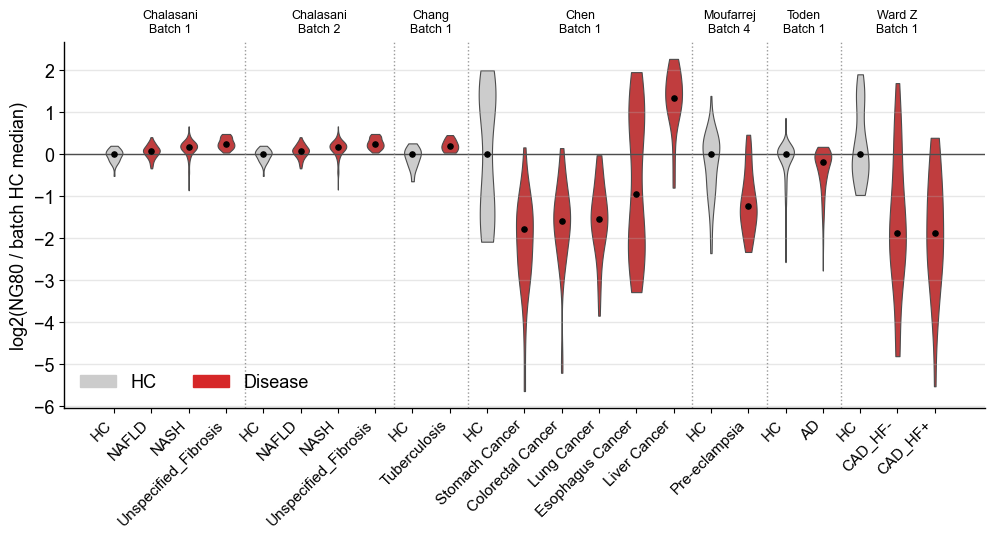

In [25]:
HC_LABEL = "Healthy Control"
METRIC = "NG80"
sig_b = df_summary.query("Bias == @METRIC and padj_FDR < 0.05").set_index("Batch")["padj_FDR"]

parts = []
for b in sig_b.index:
    g = obs[obs["Batch_ID"] == b].assign(ph=lambda d: d["Phenotype_Processed"].astype(str))
    vc = g["ph"].value_counts()
    keep = [p for p in vc.index if p != HC_LABEL and vc[p] >= 3]
    g = g[g["ph"].isin([HC_LABEL] + keep)]
    v = np.log2(g[METRIC].astype(float))
    hc_med = v[g["ph"] == HC_LABEL].median()
    parts.append(pd.DataFrame({"batch": b, "ph": g["ph"].values, "y": (v - hc_med).values}))
df_v = pd.concat(parts)
med = df_v.groupby(["batch", "ph"], sort=False)["y"].median()
grp = [(b, p) for b in sig_b.index for p in [HC_LABEL] + med[b].drop(HC_LABEL).sort_values().index.tolist()]
df_v["key"] = [f"{b}|{p}" for b, p in zip(df_v["batch"], df_v["ph"])]
keys = [f"{b}|{p}" for b, p in grp]
pal = {f"{b}|{p}": "0.8" if p == HC_LABEL else "C3" for b, p in grp}

fig, ax = plt.subplots(figsize=(0.35 * len(grp) + 2, 5.5))
sns.violinplot(data=df_v, x="key", y="y", order=keys, hue="key", palette=pal, density_norm="width", width=0.45,
               cut=0, inner=None, linewidth=0.8, legend=False, ax=ax)
ax.scatter(range(len(grp)), [med[k] for k in grp], color="k", s=14, zorder=3)
ax.axhline(0, color="0.3", lw=1)
edges = np.cumsum([sum(k[0] == b for k in grp) for b in sig_b.index])
for e in edges[:-1]:
    ax.axvline(e - 0.5, color="0.6", ls=":")
for b, lo, hi in zip(sig_b.index, np.r_[0, edges[:-1]], edges):
    ax.text((lo + hi - 1) / 2, 1.02, b.replace(" et al.", "").replace("_Batch_", "\nBatch "), transform=ax.get_xaxis_transform(),
            ha="center", va="bottom", fontsize=9)
ax.set_xticks(range(len(grp)), ["HC" if p == HC_LABEL else p for _, p in grp], rotation=45, ha="right", fontsize=11)
ax.set_xlabel("")
ax.set_ylabel(f"log2({METRIC} / batch HC median)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in ("0.8", "C3")],
          labels=["HC", "Disease"], loc="lower left", frameon=False, ncol=2)
ax.grid(alpha=0.3, axis="y", zorder=0)

fig.tight_layout()
fig.savefig(EDA_BIAS_PHENOTYPE_DIR / "ng80_direction_violin.png", bbox_inches="tight")
plt.show()